In [ ]:
# uploading the dataset
from google.colab import files
uploaded = files.upload()


Saving pima-indians-diabetes.csv to pima-indians-diabetes.csv


In [ ]:
# Import necessary libraries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

print("All libraries imported successfully!")


All libraries imported successfully!


In [ ]:
# Load the dataset correctly

columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

df = pd.read_csv(
    'pima-indians-diabetes.csv',
    header=None,
    names=columns
)

# Display first five records
print("First five records of the dataset:")
display(df.head())

# Display dataset shape
print("\nDataset Shape:")
print(df.shape)


First five records of the dataset:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset Shape:
(768, 9)


In [ ]:
#checking dataset information

print("Dataset Information:")
df.info()

print("\nStatistical Description:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum())

print("\nOutcome Distribution:")
print(df['Outcome'].value_counts())


Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Statistical Description:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000



Missing Values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome Distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


In [ ]:
# Check zero values in selected columns

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

print("Number of zero values in each column:\n")

for column in columns_to_check:
    zero_count = (df[column] == 0).sum()
    print(f"{column}: {zero_count}")


Number of zero values in each column:

Glucose: 5
BloodPressure: 35
SkinThickness: 227
Insulin: 374
BMI: 11


**DATA PREPROCESSING**

In [ ]:
# Replace invalid zero values with NaN

columns_to_check = [
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI'
]

df[columns_to_check] = df[columns_to_check].replace(0, np.nan)

print("Missing values after replacing zeros:\n")
print(df.isnull().sum())


Missing values after replacing zeros:

Pregnancies                   0
Glucose                       5
BloodPressure                35
SkinThickness               227
Insulin                     374
BMI                          11
DiabetesPedigreeFunction      0
Age                           0
Outcome                       0
dtype: int64


In [ ]:
# Separate independent and dependent variables

X = df.drop('Outcome', axis=1)
y = df['Outcome']

print("Independent Variables (X):")
display(X.head())

print("\nDependent Variable (y):")
print(y.head())



Independent Variables (X):


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age
0,6,148.0,72.0,35.0,NaN,33.6,0.627,50
1,1,85.0,66.0,29.0,NaN,26.6,0.351,31
2,8,183.0,64.0,NaN,NaN,23.3,0.672,32
3,1,89.0,66.0,23.0,94.0,28.1,0.167,21
4,0,137.0,40.0,35.0,168.0,43.1,2.288,33



Dependent Variable (y):
0    1
1    0
2    1
3    0
4    1
Name: Outcome, dtype: int64


In [ ]:
# Split dataset into training and testing sets

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))



Training records: 614
Testing records: 154


In [ ]:
# Handle missing values and apply feature scaling

preprocessor = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

X_train_scaled = preprocessor.fit_transform(X_train)
X_test_scaled = preprocessor.transform(X_test)

print("Missing values handled successfully!")
print("Feature scaling completed successfully!")

print("\nTraining data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)


Missing values handled successfully!
Feature scaling completed successfully!

Training data shape: (614, 8)
Testing data shape: (154, 8)


**KNN Model Training and Finding the Optimal K Value**

In [ ]:
# Import libraries for model selection

from sklearn.model_selection import GridSearchCV, StratifiedKFold
print("Model selection libraries imported successfully!")

Model selection libraries imported successfully!


In [ ]:
# Create a pipeline for the KNN model

knn_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler()),
    ('knn', KNeighborsClassifier())
])

print("KNN model pipeline created successfully!")

KNN model pipeline created successfully!


In [ ]:
# Find the optimal K value using GridSearchCV

param_grid = {
    'knn__n_neighbors': list(range(1, 22, 2))
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

grid_search = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    cv=cv,
    scoring='accuracy',
    n_jobs=-1
)

# Train the model using training data
grid_search.fit(X_train, y_train)

# Display the best K value and accuracy
best_k = grid_search.best_params_['knn__n_neighbors']

print("Optimal K value:", best_k)
print(f"Best Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")


Optimal K value: 13
Best Cross-Validation Accuracy: 77.52%


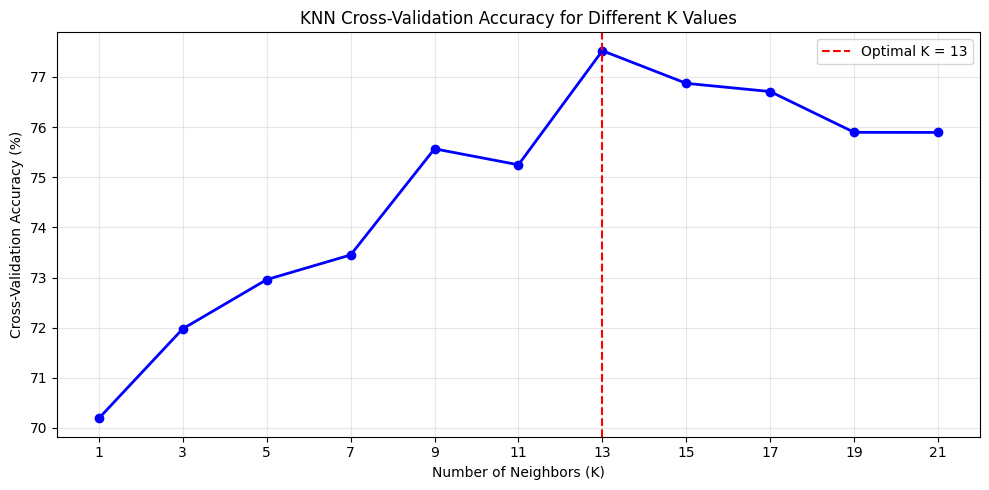

In [ ]:
# Plot cross-validation accuracy for different K values

k_values = list(range(1, 22, 2))
cv_scores = grid_search.cv_results_['mean_test_score'] * 100

plt.figure(figsize=(10, 5))

plt.plot(
    k_values,
    cv_scores,
    marker='o',
    color='blue',
    linewidth=2
)

plt.axvline(
    x=best_k,
    color='red',
    linestyle='--',
    label=f'Optimal K = {best_k}'
)

plt.title('KNN Cross-Validation Accuracy for Different K Values')
plt.xlabel('Number of Neighbors (K)')
plt.ylabel('Cross-Validation Accuracy (%)')
plt.xticks(k_values)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [ ]:
# Store the best trained KNN model

knn_model = grid_search.best_estimator_

print("KNN model trained successfully!")
print("Selected number of neighbors:", best_k)

KNN model trained successfully!
Selected number of neighbors: 13


**KNN Model Evaluation**

In [ ]:
# Import additional evaluation metrics

from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_curve,
    roc_auc_score
)

print("Evaluation libraries imported successfully!")

Evaluation libraries imported successfully!


In [ ]:
# Make predictions using the trained KNN model

y_train_pred = knn_model.predict(X_train)
y_pred = knn_model.predict(X_test)

# Predict probabilities for the positive class
y_prob = knn_model.predict_proba(X_test)[:, 1]

print("Predictions completed successfully!")
print("Total testing predictions:", len(y_pred))

print("\nFirst 10 predicted outcomes:")
print(y_pred[:10])

print("\nFirst 10 actual outcomes:")
print(y_test.values[:10])

Predictions completed successfully!
Total testing predictions: 154

First 10 predicted outcomes:
[1 0 0 0 0 0 0 1 0 1]

First 10 actual outcomes:
[0 0 0 1 0 0 1 1 0 0]


In [ ]:
# Calculate training and testing accuracy

train_accuracy = accuracy_score(y_train, y_train_pred)
test_accuracy = accuracy_score(y_test, y_pred)

print(f"Training Accuracy: {train_accuracy * 100:.2f}%")
print(f"Testing Accuracy: {test_accuracy * 100:.2f}%")
print(f"Cross-Validation Accuracy: {grid_search.best_score_ * 100:.2f}%")

Training Accuracy: 80.62%
Testing Accuracy: 71.43%
Cross-Validation Accuracy: 77.52%


In [ ]:
# Generate the confusion matrix

cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

# Extract confusion matrix values

tn, fp, fn, tp = cm.ravel()

print("\nTrue Negatives (TN):", tn)
print("False Positives (FP):", fp)
print("False Negatives (FN):", fn)
print("True Positives (TP):", tp)

Confusion Matrix:
[[82 18]
 [26 28]]

True Negatives (TN): 82
False Positives (FP): 18
False Negatives (FN): 26
True Positives (TP): 28


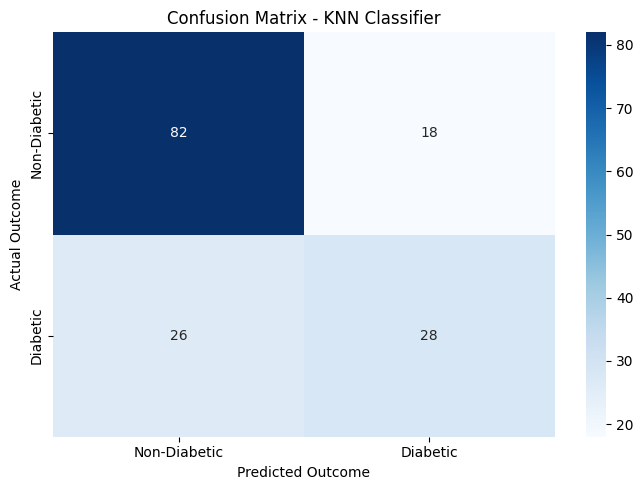

In [ ]:
# Visualize the confusion matrix

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Non-Diabetic', 'Diabetic'],
    yticklabels=['Non-Diabetic', 'Diabetic']
)

plt.title('Confusion Matrix - KNN Classifier')
plt.xlabel('Predicted Outcome')
plt.ylabel('Actual Outcome')
plt.tight_layout()
plt.show()


In [ ]:
# Calculate evaluation metrics

precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)

print("KNN Model Performance Metrics:\n")

print(f"Accuracy:  {test_accuracy * 100:.2f}%")
print(f"Precision: {precision * 100:.2f}%")
print(f"Recall:    {recall * 100:.2f}%")
print(f"F1-Score:  {f1 * 100:.2f}%")

KNN Model Performance Metrics:

Accuracy:  71.43%
Precision: 60.87%
Recall:    51.85%
F1-Score:  56.00%


In [ ]:
# Display the classification report

print("Classification Report:\n")

print(classification_report(
    y_test,
    y_pred,
    target_names=['Non-Diabetic', 'Diabetic'],
    digits=4,
    zero_division=0
))

Classification Report:

              precision    recall  f1-score   support

Non-Diabetic     0.7593    0.8200    0.7885       100
    Diabetic     0.6087    0.5185    0.5600        54

    accuracy                         0.7143       154
   macro avg     0.6840    0.6693    0.6742       154
weighted avg     0.7065    0.7143    0.7084       154



In [ ]:
# Calculate ROC-AUC score

auc_score = roc_auc_score(y_test, y_prob)

print(f"ROC-AUC Score: {auc_score:.4f}")

ROC-AUC Score: 0.7944


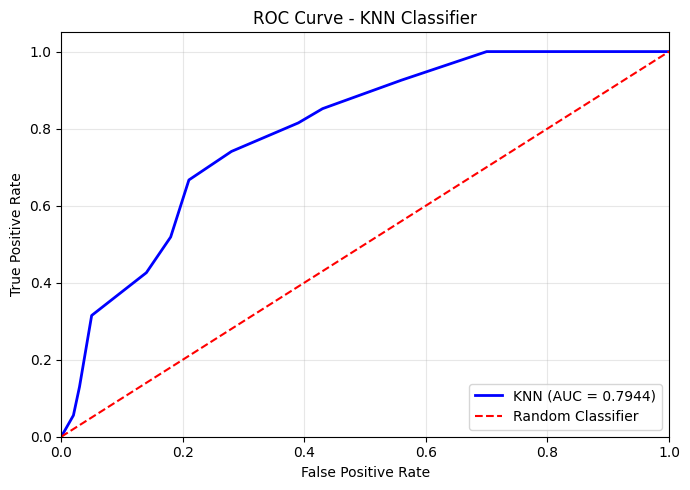

In [ ]:
# Plot the ROC curve

fpr, tpr, thresholds = roc_curve(y_test, y_prob)

plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    color='blue',
    linewidth=2,
    label=f'KNN (AUC = {auc_score:.4f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    color='red',
    linestyle='--',
    label='Random Classifier'
)

plt.title('ROC Curve - KNN Classifier')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim([0, 1])
plt.ylim([0, 1.05])
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


**EXPLORATORY DATA ANALYSIS AND VISUALIZATION**

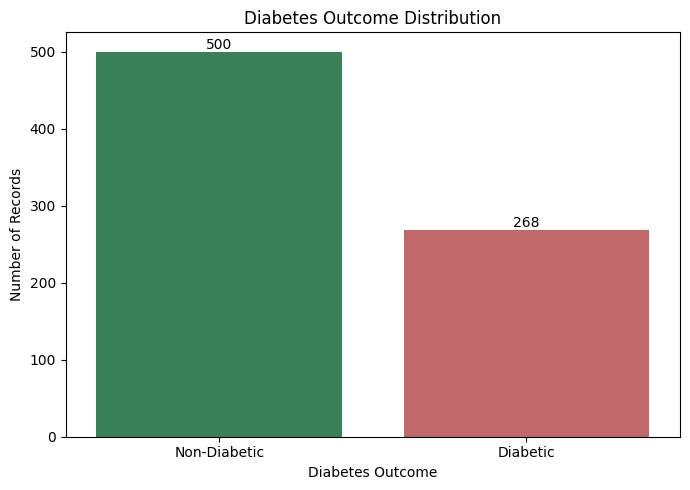

In [ ]:
# Visualize diabetes outcome distribution

plt.figure(figsize=(7, 5))

ax = sns.countplot(
    data=df,
    x='Outcome',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

for container in ax.containers:
    ax.bar_label(container)

plt.title('Diabetes Outcome Distribution')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Number of Records')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


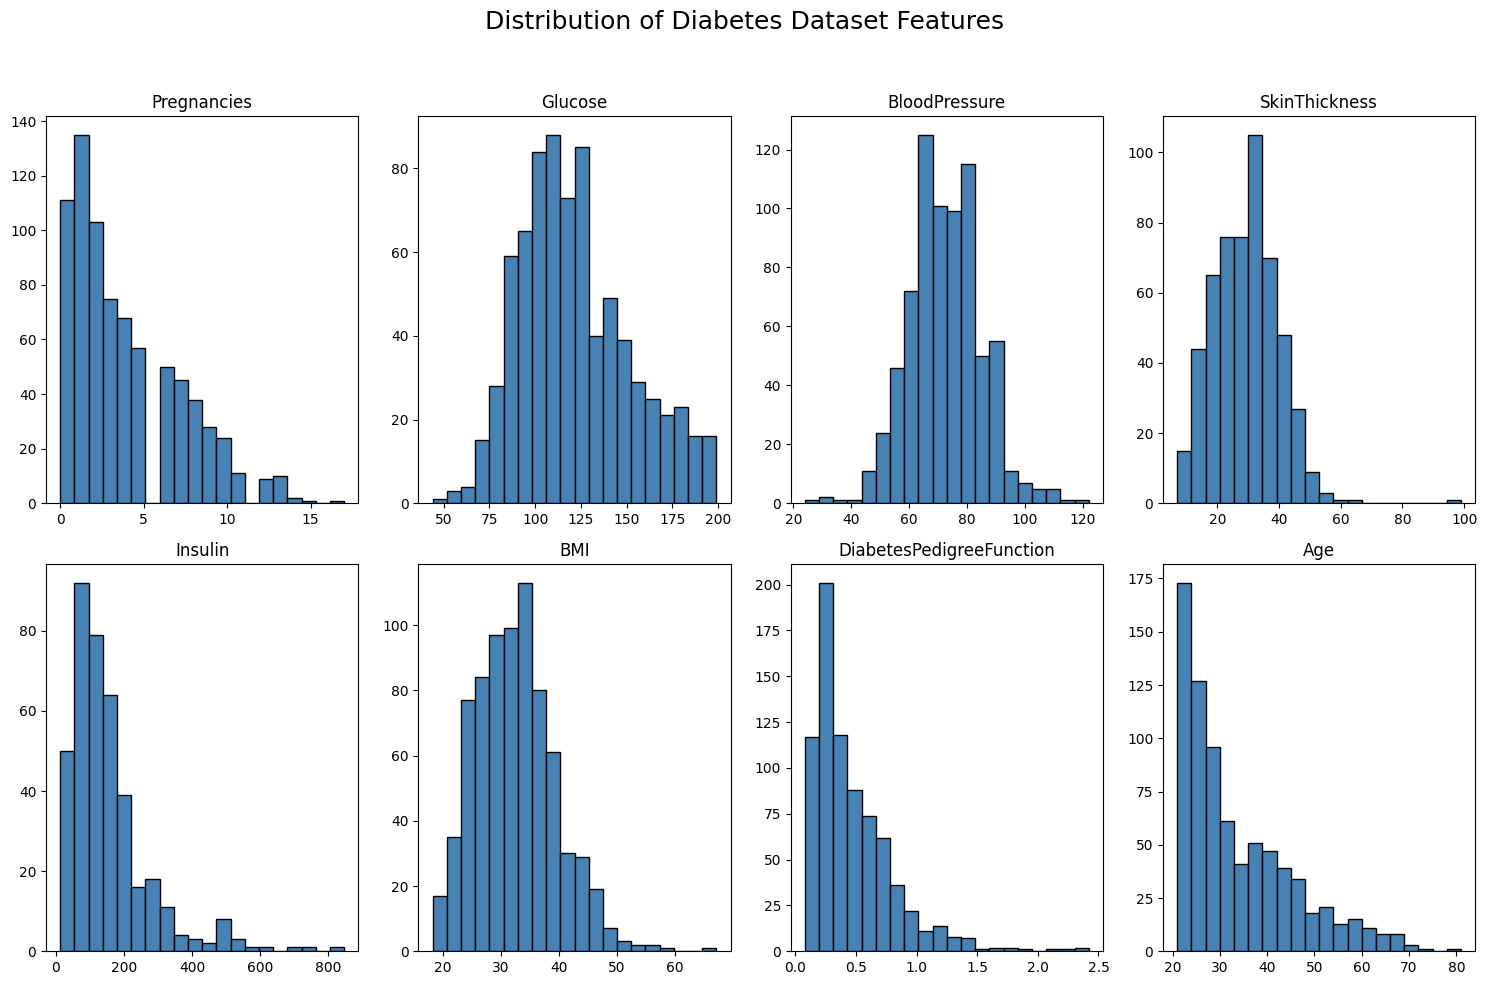

In [ ]:
# Visualize the distribution of all input features

df.drop(columns='Outcome').hist(
    figsize=(15, 10),
    bins=20,
    color='steelblue',
    edgecolor='black',
    grid=False,
    layout=(2, 4)
)

plt.suptitle(
    'Distribution of Diabetes Dataset Features',
    fontsize=18
)

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()


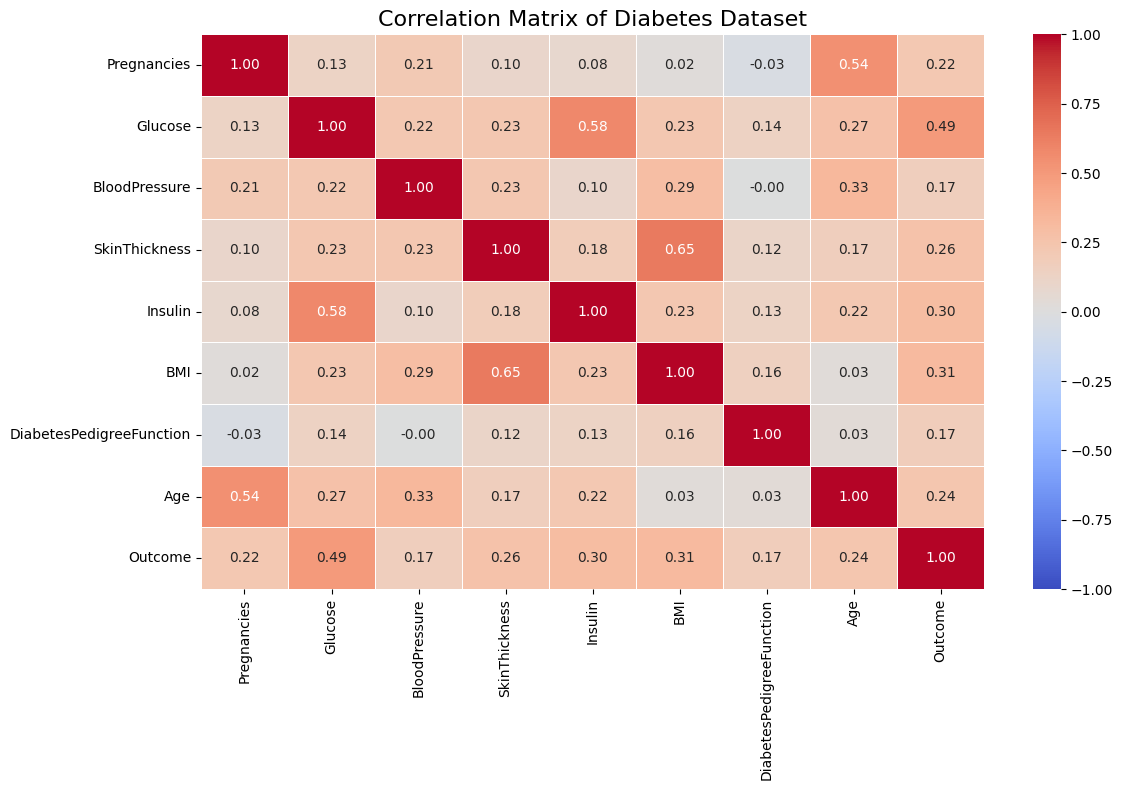

In [ ]:
# Generate correlation matrix heatmap

correlation_matrix = df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    linewidths=0.5,
    vmin=-1,
    vmax=1,
    center=0
)

plt.title('Correlation Matrix of Diabetes Dataset', fontsize=16)
plt.tight_layout()
plt.show()


In [ ]:
# Display feature correlations with diabetes outcome

outcome_correlation = (
    correlation_matrix['Outcome']
    .drop('Outcome')
    .sort_values(ascending=False)
)

print("Feature Correlations with Diabetes Outcome:\n")
print(outcome_correlation.round(4))

Feature Correlations with Diabetes Outcome:

Glucose                     0.4947
BMI                         0.3137
Insulin                     0.3035
SkinThickness               0.2595
Age                         0.2384
Pregnancies                 0.2219
DiabetesPedigreeFunction    0.1738
BloodPressure               0.1706
Name: Outcome, dtype: float64


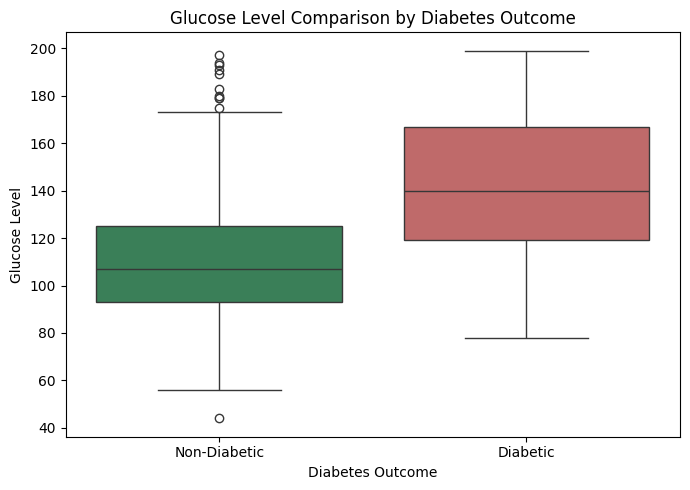

In [ ]:
# Compare glucose levels by diabetes outcome

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Outcome',
    y='Glucose',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

plt.title('Glucose Level Comparison by Diabetes Outcome')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Glucose Level')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


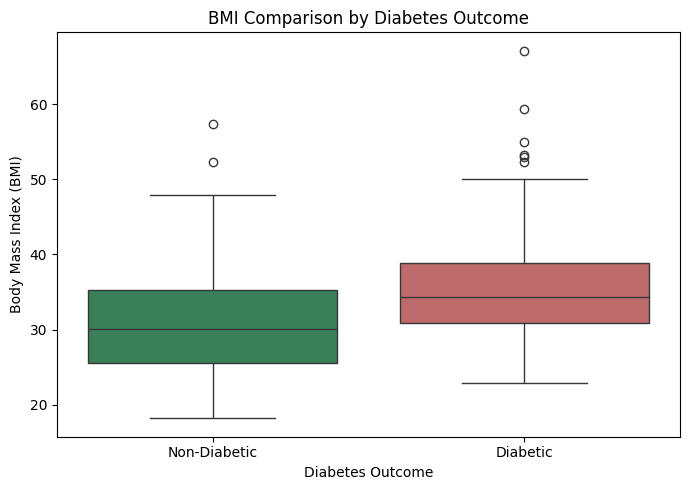

In [ ]:
# Compare BMI by diabetes outcome

plt.figure(figsize=(7, 5))

sns.boxplot(
    data=df,
    x='Outcome',
    y='BMI',
    hue='Outcome',
    palette=['seagreen', 'indianred'],
    legend=False
)

plt.title('BMI Comparison by Diabetes Outcome')
plt.xlabel('Diabetes Outcome')
plt.ylabel('Body Mass Index (BMI)')
plt.xticks([0, 1], ['Non-Diabetic', 'Diabetic'])
plt.tight_layout()
plt.show()


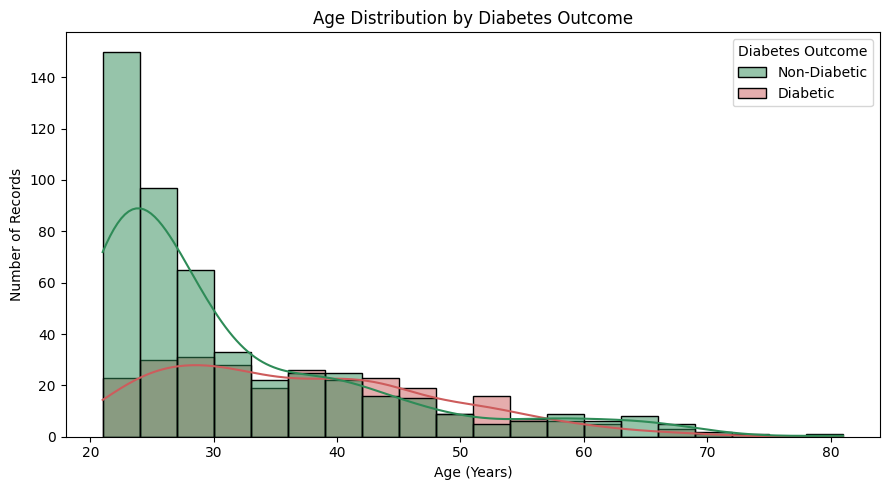

In [ ]:

# Compare age distribution by diabetes outcome

plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x='Age',
    hue='Outcome',
    hue_order=[0, 1],
    palette=['seagreen', 'indianred'],
    bins=20,
    kde=True,
    alpha=0.5,
    multiple='layer'
)

plt.title('Age Distribution by Diabetes Outcome')
plt.xlabel('Age (Years)')
plt.ylabel('Number of Records')

legend = plt.gca().get_legend()
legend.set_title('Diabetes Outcome')

for text, label in zip(
    legend.get_texts(),
    ['Non-Diabetic', 'Diabetic']
):
    text.set_text(label)

plt.tight_layout()
plt.show()


In [ ]:
# Compare average feature values by diabetes outcome

group_means = df.groupby('Outcome').mean().T

group_means.columns = ['Non-Diabetic', 'Diabetic']

print("Average Feature Values by Diabetes Outcome:\n")

display(group_means.round(2))

Average Feature Values by Diabetes Outcome:



,Non-Diabetic,Diabetic
Pregnancies,3.30,4.87
Glucose,110.64,142.32
BloodPressure,70.88,75.32
SkinThickness,27.24,33.00
Insulin,130.29,206.85
BMI,30.86,35.41
DiabetesPedigreeFunction,0.43,0.55
Age,31.19,37.07


**OBSERVATIONS FROM EXPLORATORY DATA ANALYSIS**

1. The dataset contains 768 records, including 500 non-diabetic and 268 diabetic records, indicating moderate class imbalance.

2. Glucose has the strongest positive correlation with diabetes outcome (0.4947), followed by BMI (0.3137) and Insulin (0.3035).

3. The average glucose level of diabetic records is 142.32, compared to 110.64 for non-diabetic records.

4. The diabetic group has a higher average BMI of 35.41 compared to 30.86 in the non-diabetic group.

5. The average age of the diabetic group is 37.07 years, whereas the non-diabetic group has an average age of 31.19 years.

6. Features such as Insulin, Age, Pregnancies and DiabetesPedigreeFunction exhibit right-skewed distributions.

7. The exploratory analysis reveals associations between the input features and diabetes outcome. However, correlation does not establish causation.

8. Class imbalance and overlapping feature distributions may contribute to the model's lower recall for diabetic records.

**DIABETES PREDICTION USING NEW USER INPUT**

In [ ]:
# Create a function for diabetes prediction

def predict_diabetes(input_data):

    # Convert input data into a DataFrame
    input_df = pd.DataFrame(
        [input_data],
        columns=X_train.columns
    )

    # Replace invalid zero values with NaN
    input_df[columns_to_check] = (
        input_df[columns_to_check].replace(0, np.nan)
    )

    # Predict diabetes outcome
    prediction = knn_model.predict(input_df)[0]

    # Calculate class probabilities
    probabilities = knn_model.predict_proba(input_df)[0]

    return prediction, probabilities


print("Diabetes prediction function created successfully!")


Diabetes prediction function created successfully!


In [ ]:
# Test the model with sample input data

sample_data = [
    2,       # Pregnancies
    120,     # Glucose
    72,      # Blood Pressure
    25,      # Skin Thickness
    100,     # Insulin
    28.5,    # BMI
    0.350,   # Diabetes Pedigree Function
    30       # Age
]

prediction, probabilities = predict_diabetes(sample_data)

print("Sample Diabetes Prediction:\n")

if prediction == 0:
    print("Predicted Outcome: Non-Diabetic")
else:
    print("Predicted Outcome: Diabetic")

print(f"\nNon-Diabetic Probability: {probabilities[0] * 100:.2f}%")
print(f"Diabetic Probability: {probabilities[1] * 100:.2f}%")


Sample Diabetes Prediction:

Predicted Outcome: Non-Diabetic

Non-Diabetic Probability: 61.54%
Diabetic Probability: 38.46%


In [ ]:
# Accept user input for diabetes prediction

print("=" * 50)
print("       DIABETES PREDICTION USING KNN")
print("=" * 50)

print("\nEnter the following details:\n")

try:
    pregnancies = int(input("Number of Pregnancies: "))
    glucose = float(input("Glucose Level: "))
    blood_pressure = float(input("Blood Pressure: "))
    skin_thickness = float(input("Skin Thickness: "))
    insulin = float(input("Insulin Level: "))
    bmi = float(input("BMI: "))
    dpf = float(input("Diabetes Pedigree Function: "))
    age = int(input("Age: "))

    user_data = [
        pregnancies,
        glucose,
        blood_pressure,
        skin_thickness,
        insulin,
        bmi,
        dpf,
        age
    ]

    # Validate input values
    if any(not np.isfinite(value) or value < 0
           for value in user_data):
        print("\nInvalid input! Enter finite, non-negative values.")

    elif age < 21:
        print("\nInvalid input! This dataset represents adults aged 21 or above.")

    else:
        # Generate prediction
        prediction, probabilities = predict_diabetes(user_data)

        print("\n" + "=" * 50)
        print("              PREDICTION RESULT")
        print("=" * 50)

        if prediction == 0:
            print("\nPredicted Outcome: Non-Diabetic")
        else:
            print("\nPredicted Outcome: Diabetic")

        print(f"\nNon-Diabetic Probability: {probabilities[0] * 100:.2f}%")
        print(f"Diabetic Probability: {probabilities[1] * 100:.2f}%")

        print("\nOptimal K Value:", best_k)

        print("=" * 50)

except ValueError:
    print("\nInvalid input! Please enter numerical values.")


       DIABETES PREDICTION USING KNN

Enter the following details:

Number of Pregnancies: 1
Glucose Level: 95
Blood Pressure: 70
Skin Thickness: 20
Insulin Level: 85
BMI: 23.5
Diabetes Pedigree Function: 0.200
Age: 25

              PREDICTION RESULT

Predicted Outcome: Non-Diabetic

Non-Diabetic Probability: 100.00%
Diabetic Probability: 0.00%

Optimal K Value: 13


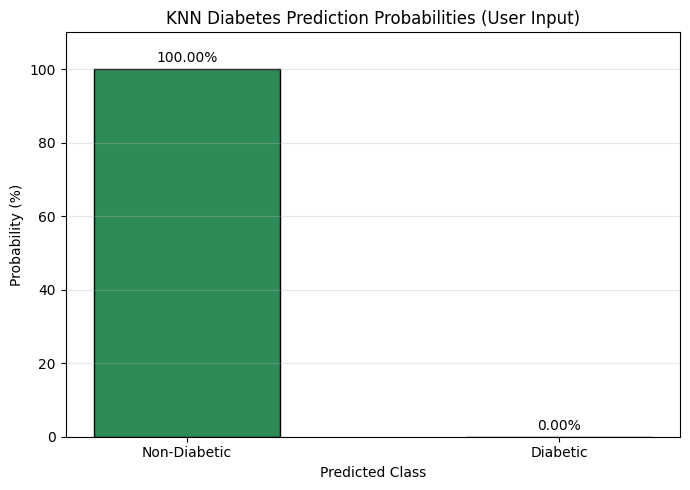

In [ ]:
# Visualize user input prediction probabilities

user_prediction, user_probabilities = predict_diabetes(
    user_data
)

labels = ['Non-Diabetic', 'Diabetic']
probability_values = user_probabilities * 100

plt.figure(figsize=(7, 5))

bars = plt.bar(
    labels,
    probability_values,
    color=['seagreen', 'indianred'],
    width=0.5,
    edgecolor='black'
)

plt.bar_label(
    bars,
    fmt='%.2f%%',
    padding=3
)

plt.title('KNN Diabetes Prediction Probabilities (User Input)')
plt.xlabel('Predicted Class')
plt.ylabel('Probability (%)')
plt.ylim(0, 110)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()
